In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

import tensorflow as tf
import keras
from keras import layers, ops

from transformers import AutoTokenizer

from datasets import Dataset
from datasets import load_dataset

In [2]:
ds = load_dataset("rajpurkar/squad_v2")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

squad_v2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

squad_v2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

squad_v2/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 1.35MB            

squad_v2/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

In [ ]:
print(ds)

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 130319
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 11873
    })
})


In [4]:
train_df = ds['train'].to_pandas()
val_df = ds['validation'].to_pandas()

In [ ]:
train_df.head()

,id,title,context,question,answers
0,56be85543aeaaa14008c9063,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,When did Beyonce start becoming popular?,"{'text': ['in the late 1990s'], 'answer_start'..."
1,56be85543aeaaa14008c9065,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,What areas did Beyonce compete in when she was...,"{'text': ['singing and dancing'], 'answer_star..."
2,56be85543aeaaa14008c9066,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,When did Beyonce leave Destiny's Child and bec...,"{'text': ['2003'], 'answer_start': [526]}"
3,56bf6b0f3aeaaa14008c9601,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,In what city and state did Beyonce grow up?,"{'text': ['Houston, Texas'], 'answer_start': [..."
4,56bf6b0f3aeaaa14008c9602,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,In which decade did Beyonce become famous?,"{'text': ['late 1990s'], 'answer_start': [276]}"


In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130319 entries, 0 to 130318
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   id        130319 non-null  object
 1   title     130319 non-null  object
 2   context   130319 non-null  object
 3   question  130319 non-null  object
 4   answers   130319 non-null  object
dtypes: object(5)
memory usage: 5.0+ MB


In [ ]:
val_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11873 entries, 0 to 11872
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        11873 non-null  object
 1   title     11873 non-null  object
 2   context   11873 non-null  object
 3   question  11873 non-null  object
 4   answers   11873 non-null  object
dtypes: object(5)
memory usage: 463.9+ KB


In [ ]:
print("Question:", train_df.iloc[0]['question'])
print("Answer:", train_df.iloc[0]['answers']['text'][0])

Question: When did Beyonce start becoming popular?
Answer: in the late 1990s


In [ ]:
train_df['is_answerable'] = train_df['answers'].apply(lambda x: len(x['text']) > 0)

print(train_df['is_answerable'].value_counts())
print(train_df['is_answerable'].value_counts(normalize = True) * 100)

is_answerable
True     86821
False    43498
Name: count, dtype: int64
is_answerable
True     66.621905
False    33.378095
Name: proportion, dtype: float64


In [ ]:
val_df['is_answerable'] = val_df['answers'].apply(lambda x: len(x['text']) > 0)

print(val_df['is_answerable'].value_counts())
print(val_df['is_answerable'].value_counts(normalize = True) * 100)

is_answerable
False    5945
True     5928
Name: count, dtype: int64
is_answerable
False    50.071591
True     49.928409
Name: proportion, dtype: float64


In [11]:
for name, df in [('Train', train_df), ('Validation', val_df)]:
    df['context_words'] = df['context'].apply(lambda x: len(x.split()))
    df['question_words'] = df['question'].apply(lambda x: len(x.split()))

    df['answer_words'] = df['answers'].apply(
        lambda x: len(x['text'][0].split()) if len(x['text']) > 0 else 0
    )

    print(f"\n{name} Dataset")
    print(df[['context_words', 'question_words', 'answer_words']].describe(
        percentiles = [0.50, 0.75, 0.90, 0.95, 0.99]
    ))


Train Dataset
       context_words  question_words   answer_words
count  130319.000000   130319.000000  130319.000000
mean      119.614316        9.893822       2.107099
std        49.404411        3.418829       3.144031
min        20.000000        1.000000       0.000000
50%       110.000000        9.000000       1.000000
75%       141.000000       12.000000       3.000000
90%       182.000000       14.000000       5.000000
95%       212.000000       16.000000       8.000000
99%       285.000000       20.000000      17.000000
max       653.000000       40.000000      43.000000

Validation Dataset
       context_words  question_words  answer_words
count   11873.000000    11873.000000  11873.000000
mean      127.907184       10.019624      1.598922
std        57.299074        3.488700      2.845115
min        25.000000        3.000000      0.000000
50%       114.000000       10.000000      0.000000
75%       148.000000       12.000000      2.000000
90%       191.000000       15.000000

In [ ]:
sample = train_df[train_df['is_answerable']].iloc[0]

context = sample['context']
answer = sample['answers']['text'][0]
answer_start = sample['answers']['answer_start'][0]

print("Answer:", answer)
print("Answer start:", answer_start)
print("Extracted text:", context[answer_start:answer_start + len(answer)])

Answer: in the late 1990s
Answer start: 269
Extracted text: in the late 1990s


In [13]:
def check_alignment(row):
    for answer, start in zip(
        row['answers']['text'],
        row['answers']['answer_start']
    ):
        if row['context'][start:start + len(answer)] != answer:
            return False
    return True

alignment = train_df[train_df['is_answerable']].apply(
    check_alignment, axis=1
)

print(alignment.value_counts())
print("Mismatch percentage:", (~alignment).mean() * 100)

True    86821
Name: count, dtype: int64
Mismatch percentage: 0.0


In [14]:
tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased"
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [15]:
sample = train_df.iloc[0]

question = sample['question']
context = sample['context']
answer = sample['answers']

print("Question:", question)
print("Context:", context)
print("Answer:", answer)

Question: When did Beyonce start becoming popular?
Context: Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ bee-YON-say) (born September 4, 1981) is an American singer, songwriter, record producer and actress. Born and raised in Houston, Texas, she performed in various singing and dancing competitions as a child, and rose to fame in the late 1990s as lead singer of R&B girl-group Destiny's Child. Managed by her father, Mathew Knowles, the group became one of the world's best-selling girl groups of all time. Their hiatus saw the release of Beyoncé's debut album, Dangerously in Love (2003), which established her as a solo artist worldwide, earned five Grammy Awards and featured the Billboard Hot 100 number-one singles "Crazy in Love" and "Baby Boy".
Answer: {'text': array(['in the late 1990s'], dtype=object), 'answer_start': array([269], dtype=int32)}


In [16]:
question = sample["question"]

inputs = tokenizer(
    question,
    context,
    return_offsets_mapping=True
)

In [17]:
answer_text = sample['answers']['text'][0]
answer_start = sample['answers']['answer_start'][0]
answer_end = answer_start + len(answer_text)

offsets = inputs['offset_mapping']
sequence_ids = inputs.sequence_ids()

start_position = end_position = None

for i, (start, end) in enumerate(offsets):
    if sequence_ids[i] != 1:
        continue

    if start <= answer_start < end:
        start_position = i

    if start < answer_end <= end:
        end_position = i

print("Answer:", answer_text)
print("Start position:", start_position)
print("End position:", end_position)

tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'])

print("Predicted answer tokens:", tokens[start_position:end_position + 1])

Answer: in the late 1990s
Start position: 75
End position: 78
Predicted answer tokens: ['in', 'the', 'late', '1990s']


In [18]:
MAX_LENGTH = 384
STRIDE = 128

def preprocess_batch(examples):

    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        max_length=MAX_LENGTH,
        truncation="only_second",
        stride=STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length"
    )

    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offset_mapping = tokenized.pop("offset_mapping")

    start_positions = []
    end_positions = []

    for i, offsets in enumerate(offset_mapping):

        sample_idx = sample_mapping[i]
        answers = examples["answers"][sample_idx]

        cls_index = tokenized["input_ids"][i].index(
            tokenizer.cls_token_id
        )

        sequence_ids = tokenized.sequence_ids(i)

        # Unanswerable example
        if len(answers["text"]) == 0:
            start_positions.append(cls_index)
            end_positions.append(cls_index)
            continue

        start_char = answers["answer_start"][0]
        end_char = start_char + len(answers["text"][0])

        # Find context token boundaries
        context_indices = [
            j for j, seq_id in enumerate(sequence_ids)
            if seq_id == 1
        ]

        if not context_indices:
            start_positions.append(cls_index)
            end_positions.append(cls_index)
            continue

        token_start = context_indices[0]
        token_end = context_indices[-1]

        # Answer not contained in this window
        if (offsets[token_start][0] > start_char or
            offsets[token_end][1] < end_char):

            start_positions.append(cls_index)
            end_positions.append(cls_index)
            continue

        # Find start token
        while (token_start <= token_end and
               offsets[token_start][0] <= start_char):
            token_start += 1

        start_position = token_start - 1

        # Find end token
        while (token_end >= start_position and
               offsets[token_end][1] >= end_char):
            token_end -= 1

        end_position = token_end + 1

        start_positions.append(start_position)
        end_positions.append(end_position)

    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions

    return tokenized

In [19]:

train_dataset = Dataset.from_pandas(train_df,preserve_index=False)

val_dataset = Dataset.from_pandas(val_df,preserve_index=False)

train_features = train_dataset.map(
    preprocess_batch,
    batched=True,
    batch_size=500,
    remove_columns=train_dataset.column_names
)

val_features = val_dataset.map(
    preprocess_batch,
    batched=True,
    batch_size=500,
    remove_columns=val_dataset.column_names
)

print("Training features:", len(train_features))
print("Validation features:", len(val_features))

Map:   0%|          | 0/130319 [00:00<?, ? examples/s]

Map:   0%|          | 0/11873 [00:00<?, ? examples/s]

Training features: 131754
Validation features: 12134


In [20]:
print(train_features[0].keys())

print("Input length:", len(train_features[0]["input_ids"]))
print("Vocabulary size:", tokenizer.vocab_size)

dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'start_positions', 'end_positions'])
Input length: 384
Vocabulary size: 30522


In [21]:
VOCAB_SIZE = tokenizer.vocab_size
MAX_LENGTH = 384
D_MODEL = 96
NUM_HEADS = 4
FF_DIM = 192
NUM_BLOCKS = 2
DROPOUT = 0.1

In [22]:
class TransformerEmbedding(layers.Layer):

    def __init__(self, vocab_size, max_length, d_model):
        super().__init__()

        self.token_embedding = layers.Embedding(
            vocab_size, d_model
        )

        self.position_embedding = layers.Embedding(
            max_length, d_model
        )

        self.segment_embedding = layers.Embedding(
            2, d_model
        )

    def call(self, inputs):

        input_ids, token_type_ids = inputs

        seq_len = tf.shape(input_ids)[1]

        positions = tf.range(start=0, limit=seq_len)

        token_emb = self.token_embedding(input_ids)
        position_emb = self.position_embedding(positions)
        segment_emb = self.segment_embedding(token_type_ids)

        return token_emb + position_emb + segment_emb

In [23]:
class TransformerBlock(layers.Layer):

    def __init__(self, d_model, num_heads, ff_dim, dropout=0.1):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=d_model // num_heads,
            dropout=dropout
        )

        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dense(d_model)
        ])

        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)

    def call(self, inputs, training=None):

        x, attention_mask = inputs

        mask = tf.broadcast_to(
            attention_mask[:, tf.newaxis, :],
            [
                tf.shape(attention_mask)[0],
                tf.shape(attention_mask)[1],
                tf.shape(attention_mask)[1]
            ]
        )

        attention_output = self.attention(
            query=x,
            value=x,
            key=x,
            attention_mask=mask,
            training=training
        )

        x = self.norm1(
            x + self.dropout1(attention_output, training=training)
        )

        ffn_output = self.ffn(x, training=training)

        x = self.norm2(
            x + self.dropout2(ffn_output, training=training)
        )

        return x

In [24]:
class MaskLogits(layers.Layer):

    def call(self, inputs):

        logits, attention_mask = inputs

        return tf.where(
            attention_mask == 1,
            logits,
            tf.cast(-1e9, logits.dtype)
        )

In [25]:
input_ids = keras.Input(
    shape=(MAX_LENGTH,),
    dtype=tf.int32,
    name="input_ids"
)

token_type_ids = keras.Input(
    shape=(MAX_LENGTH,),
    dtype=tf.int32,
    name="token_type_ids"
)

attention_mask = keras.Input(
    shape=(MAX_LENGTH,),
    dtype=tf.int32,
    name="attention_mask"
)

x = TransformerEmbedding(
    VOCAB_SIZE,
    MAX_LENGTH,
    D_MODEL
)([input_ids, token_type_ids])

x = layers.Dropout(DROPOUT)(x)

for _ in range(NUM_BLOCKS):

    x = TransformerBlock(
        D_MODEL,
        NUM_HEADS,
        FF_DIM,
        DROPOUT
    )([x, attention_mask])

start_logits = layers.Dense(1, name="start_head")(x)
end_logits = layers.Dense(1, name="end_head")(x)

start_logits = layers.Reshape((MAX_LENGTH,))(start_logits)
end_logits = layers.Reshape((MAX_LENGTH,))(end_logits)

start_logits = MaskLogits()([start_logits, attention_mask])
end_logits = MaskLogits()([end_logits, attention_mask])

model = keras.Model(
    inputs={
        "input_ids": input_ids,
        "token_type_ids": token_type_ids,
        "attention_mask": attention_mask
    },
    outputs={
        "start_logits": start_logits,
        "end_logits": end_logits
    }
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 384)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_type_ids      │ (None, 384)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_embedd… │ (None, 384, 96)   │  2,967,168 │ input_ids[0][0],  │
│ (TransformerEmbedd… │                   │            │ token_type_ids[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 384, 96)   │          0 │ transformer_embe… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_mask      │ (None, 384)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block   │ (None, 384, 96)   │     74,784 │ dropout[0][0],    │
│ (TransformerBlock)  │                   │            │ attention_mask[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_1 │ (None, 384, 96)   │     74,784 │ transformer_bloc… │
│ (TransformerBlock)  │                   │            │ attention_mask[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ end_head (Dense)    │ (None, 384, 1)    │         97 │ transformer_bloc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ start_head (Dense)  │ (None, 384, 1)    │         97 │ transformer_bloc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 384)       │          0 │ end_head[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 384)       │          0 │ start_head[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask_logits_1       │ (None, 384)       │          0 │ reshape_1[0][0],  │
│ (MaskLogits)        │                   │            │ attention_mask[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask_logits         │ (None, 384)       │          0 │ reshape[0][0],    │
│ (MaskLogits)        │                   │            │ attention_mask[0… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,116,930 (11.89 MB)

 Trainable params: 3,116,930 (11.89 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-4),

    loss={
        "start_logits": keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        "end_logits": keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        )
    },

    metrics={
        "start_logits": ["sparse_categorical_accuracy"],
        "end_logits": ["sparse_categorical_accuracy"]
    }
)

In [27]:
def create_tf_dataset(dataset, batch_size=64, shuffle=False):

    inputs = {
        "input_ids": np.array(dataset["input_ids"], dtype=np.int32),
        "token_type_ids": np.array(dataset["token_type_ids"], dtype=np.int32),
        "attention_mask": np.array(dataset["attention_mask"], dtype=np.int32)
    }

    labels = {
        "start_logits": np.array(dataset["start_positions"], dtype=np.int32),
        "end_logits": np.array(dataset["end_positions"], dtype=np.int32)
    }

    ds = tf.data.Dataset.from_tensor_slices((inputs, labels))

    if shuffle:
        ds = ds.shuffle(10000)

    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


BATCH_SIZE = 64

train_tf = create_tf_dataset(
    train_features, BATCH_SIZE, shuffle=True
)

val_tf = create_tf_dataset(
    val_features, BATCH_SIZE
)

In [28]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose = 1
    ),

    keras.callbacks.ModelCheckpoint(
        "custom_squad_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

In [29]:
history = model.fit(
    train_tf,
    validation_data=val_tf,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
2059/2059 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - end_logits_loss: 3.5923 - end_logits_sparse_categorical_accuracy: 0.2970 - loss: 7.2651 - start_logits_loss: 3.6727 - start_logits_sparse_categorical_accuracy: 0.2982
Epoch 1: val_loss improved from None to 5.69498, saving model to custom_squad_best.keras

Epoch 1: finished saving model to custom_squad_best.keras
2059/2059 ━━━━━━━━━━━━━━━━━━━━ 140s 59ms/step - end_logits_loss: 3.4078 - end_logits_sparse_categorical_accuracy: 0.3391 - loss: 6.8970 - start_logits_loss: 3.4890 - start_logits_sparse_categorical_accuracy: 0.3394 - val_end_logits_loss: 2.8158 - val_end_logits_sparse_categorical_accuracy: 0.5021 - val_loss: 5.6950 - val_start_logits_loss: 2.8786 - val_start_logits_sparse_categorical_accuracy: 0.5021 - learning_rate: 2.0000e-04
Epoch 2/8
2058/2059 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - end_logits_loss: 3.0771 - end_logits_sparse_categorical_accuracy: 0.3134 - loss: 6.2453 - start_logits_loss: 3.1683 - start_logits_sparse_cat

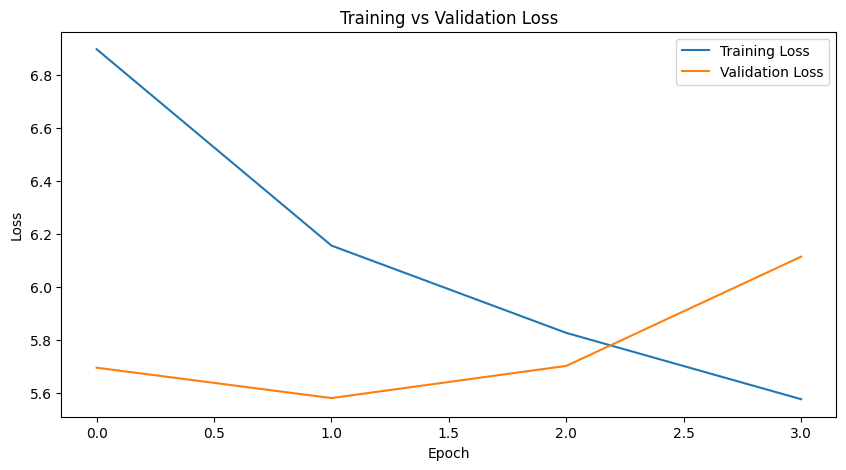

In [31]:
history_dict = history.history

plt.figure(figsize=(10, 5))
plt.plot(history_dict["loss"], label="Training Loss")
plt.plot(history_dict["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

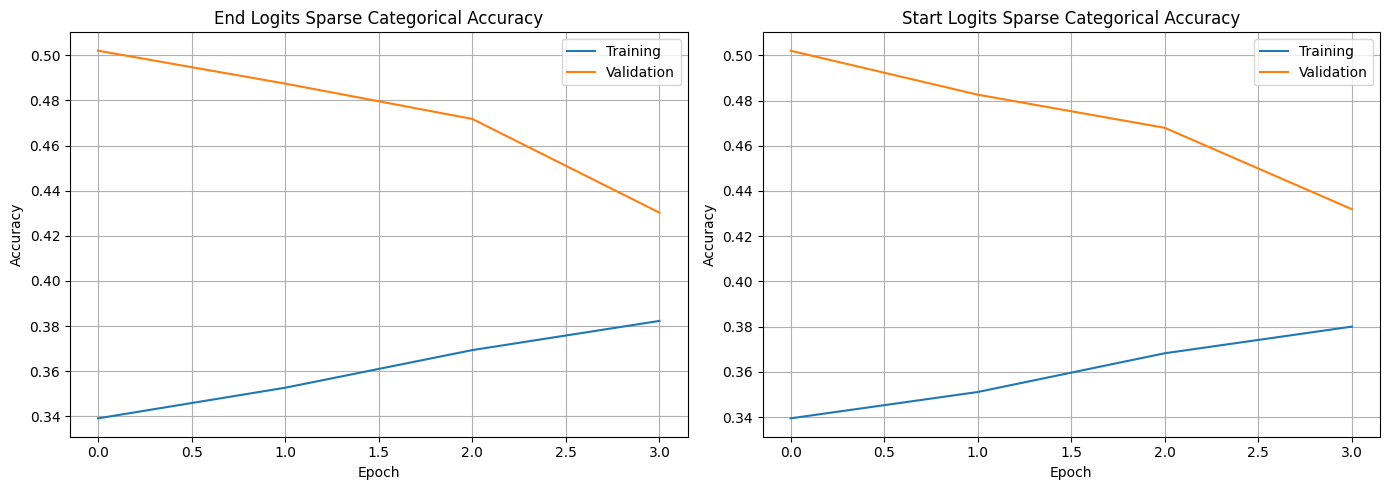

In [32]:
accuracy_keys = [
    key for key in history_dict
    if "sparse_categorical_accuracy" in key
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, accuracy_keys[:2]):

    val_metric = "val_" + metric

    ax.plot(history_dict[metric], label="Training")
    ax.plot(history_dict[val_metric], label="Validation")

    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

In [33]:
def preprocess_eval_batch(examples):

    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        max_length=MAX_LENGTH,
        truncation="only_second",
        stride=STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length"
    )

    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offsets = tokenized.pop("offset_mapping")

    tokenized["example_id"] = [
        examples["id"][idx] for idx in sample_mapping
    ]

    cleaned_offsets = []

    for i, feature_offsets in enumerate(offsets):

        sequence_ids = tokenized.sequence_ids(i)

        cleaned = [
            offset if sequence_ids[j] == 1 else (0, 0)
            for j, offset in enumerate(feature_offsets)
        ]

        cleaned_offsets.append(cleaned)

    tokenized["offset_mapping"] = cleaned_offsets

    return tokenized


eval_features = val_dataset.map(
    preprocess_eval_batch,
    batched=True,
    batch_size=500,
    remove_columns=val_dataset.column_names
)

print("Evaluation windows:", len(eval_features))

Map:   0%|          | 0/11873 [00:00<?, ? examples/s]

Evaluation windows: 12134


In [34]:
eval_inputs = {
    "input_ids": np.array(
        eval_features["input_ids"], dtype=np.int32
    ),
    "token_type_ids": np.array(
        eval_features["token_type_ids"], dtype=np.int32
    ),
    "attention_mask": np.array(
        eval_features["attention_mask"], dtype=np.int32
    )
}

eval_tf = tf.data.Dataset.from_tensor_slices(
    eval_inputs
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

predictions = model.predict(eval_tf, verbose=1)

start_logits = predictions["start_logits"]
end_logits = predictions["end_logits"]

190/190 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step


In [35]:
eval_inputs = {
    "input_ids": np.array(
        eval_features["input_ids"], dtype=np.int32
    ),
    "token_type_ids": np.array(
        eval_features["token_type_ids"], dtype=np.int32
    ),
    "attention_mask": np.array(
        eval_features["attention_mask"], dtype=np.int32
    )
}

eval_tf = tf.data.Dataset.from_tensor_slices(
    eval_inputs
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

predictions = model.predict(eval_tf, verbose=1)

start_logits = predictions["start_logits"]
end_logits = predictions["end_logits"]

190/190 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step


In [36]:
from collections import defaultdict

MAX_ANSWER_LENGTH = 30
TOP_K = 20

example_predictions = defaultdict(
    lambda: {
        "best_score": -float("inf"),
        "best_answer": "",
        "null_score": float("inf")
    }
)

for i, feature in enumerate(eval_features):

    example_id = feature["example_id"]
    offsets = feature["offset_mapping"]
    input_ids = feature["input_ids"]

    cls_index = input_ids.index(tokenizer.cls_token_id)

    # Null answer score
    null_score = (
        start_logits[i][cls_index] +
        end_logits[i][cls_index]
    )

    example_predictions[example_id]["null_score"] = min(
        example_predictions[example_id]["null_score"],
        float(null_score)
    )

    context_indices = [
        j for j, offset in enumerate(offsets)
        if offset[1] > offset[0]
    ]

    start_indexes = np.argsort(-start_logits[i])[:TOP_K]
    end_indexes = np.argsort(-end_logits[i])[:TOP_K]

    for start in start_indexes:

        for end in end_indexes:

            if start not in context_indices:
                continue

            if end not in context_indices:
                continue

            if end < start:
                continue

            if end - start + 1 > MAX_ANSWER_LENGTH:
                continue

            start_char = offsets[start][0]
            end_char = offsets[end][1]

            score = (
                start_logits[i][start] +
                end_logits[i][end]
            )

            if score > example_predictions[example_id]["best_score"]:

                context = val_df.loc[
                    val_df["id"] == example_id, "context"
                ].iloc[0]

                example_predictions[example_id]["best_score"] = float(score)

                example_predictions[example_id]["best_answer"] = (
                    context[start_char:end_char]
                )

In [37]:
import re
import string

def normalize_answer(text):

    text = text.lower()

    text = "".join(
        char for char in text
        if char not in string.punctuation
    )

    text = re.sub(r"\b(a|an|the)\b", " ", text)

    return " ".join(text.split())


def exact_match(prediction, ground_truth):

    return int(
        normalize_answer(prediction) ==
        normalize_answer(ground_truth)
    )


def token_f1(prediction, ground_truth):

    pred_tokens = normalize_answer(prediction).split()
    gold_tokens = normalize_answer(ground_truth).split()

    if not pred_tokens or not gold_tokens:
        return int(pred_tokens == gold_tokens)

    common = set(pred_tokens) & set(gold_tokens)

    # Account for repeated tokens
    from collections import Counter

    common_count = sum(
        (Counter(pred_tokens) & Counter(gold_tokens)).values()
    )

    if common_count == 0:
        return 0.0

    precision = common_count / len(pred_tokens)
    recall = common_count / len(gold_tokens)

    return 2 * precision * recall / (precision + recall)

In [40]:
results = []

for _, row in val_df.iterrows():

    example_id = row["id"]
    answers = row["answers"]["text"]

    pred_info = example_predictions[example_id]

    score_diff = (
        pred_info["null_score"] -
        pred_info["best_score"]
    )

    prediction = (
        ""
        if score_diff > 0
        else pred_info["best_answer"]
    )

    gold_answers = list(answers) if len(answers) > 0 else [""]

    em = max(
        exact_match(prediction, gold)
        for gold in gold_answers
    )

    f1 = max(
        token_f1(prediction, gold)
        for gold in gold_answers
    )

    results.append({
        "id": example_id,
        "prediction": prediction,
        "gold_answer": gold_answers[0],
        "exact_match": em,
        "f1": f1
    })

results_df = pd.DataFrame(results)

print(f"Exact Match: {results_df['exact_match'].mean() * 100:.2f}%")
print(f"F1 Score:    {results_df['f1'].mean() * 100:.2f}%")

Exact Match: 47.60%
F1 Score:    47.87%


In [41]:
for _, row in results_df.sample(10, random_state=42).iterrows():

    print("=" * 80)
    print("QUESTION:", val_df.loc[
        val_df["id"] == row["id"], "question"
    ].iloc[0])

    print("ACTUAL ANSWER:", row["gold_answer"])
    print("PREDICTED ANSWER:", row["prediction"])
    print("EM:", row["exact_match"], "| F1:", round(row["f1"], 3))

QUESTION: What did objects in forced motion contain according to the late Medieval idea that influence Aristotle?
ACTUAL ANSWER: impetus
PREDICTED ANSWER: 
EM: 0 | F1: 0.0
QUESTION: What was thought to decide a person's behavior?
ACTUAL ANSWER: the environment in which they lived
PREDICTED ANSWER: 
EM: 0 | F1: 0.0
QUESTION: What makes the method of trial division more efficient?
ACTUAL ANSWER: if a complete list of primes up to  is known
PREDICTED ANSWER: 
EM: 0 | F1: 0.0
QUESTION: What makes up 49.2% of the sun's mass?
ACTUAL ANSWER: 
PREDICTED ANSWER: 
EM: 1 | F1: 1.0
QUESTION: What is not a problem?
ACTUAL ANSWER: 
PREDICTED ANSWER: 
EM: 1 | F1: 1.0
QUESTION: What have CT scans lead to for doctors and their patients?
ACTUAL ANSWER: 
PREDICTED ANSWER: 
EM: 1 | F1: 1.0
QUESTION: When was the joint statement on climate change issued?
ACTUAL ANSWER: 2001
PREDICTED ANSWER: 
EM: 0 | F1: 0.0
QUESTION: What does not depend on the immune system's ability to distinguish between the self and o

In [43]:
print("Total validation examples:", len(results_df))

print(
    "Empty predictions:",
    (results_df["prediction"] == "").sum()
)

print(
    "Non-empty predictions:",
    (results_df["prediction"] != "").sum()
)

print(
    "Empty prediction percentage:",
    round(
        (results_df["prediction"] == "").mean() * 100, 2
    ),
    "%"
)

Total validation examples: 11873
Empty predictions: 11131
Non-empty predictions: 742
Empty prediction percentage: 93.75 %


In [42]:
print("\nCUSTOM TRANSFORMER — SQUAD 2.0")
print("-" * 45)

print("Parameters:", f"{model.count_params():,}")
print("Training features:", len(train_features))
print("Validation examples:", len(val_df))

print(f"Exact Match: {results_df['exact_match'].mean() * 100:.2f}%")
print(f"F1 Score:    {results_df['f1'].mean() * 100:.2f}%")


CUSTOM TRANSFORMER — SQUAD 2.0
---------------------------------------------
Parameters: 3,116,930
Training features: 131754
Validation examples: 11873
Exact Match: 47.60%
F1 Score:    47.87%
